# Level 3 · Task 3 — Neural Network with TensorFlow / Keras
**Codveda Technology — Machine Learning Internship**

**Goal:** build a simple **feed-forward neural network** for a classification task. We use the provided telecom churn data
(predict whether a customer will leave) — a binary classification problem on tabular data.

**Dataset:** `churn-bigml-80.csv` (train + validation) and `churn-bigml-20.csv` (held-out test).

**Objectives covered**
1. Load and preprocess the dataset
2. Design a neural-network architecture (input layer, hidden layers, output layer)
3. Train the model with backpropagation (Adam optimiser, binary cross-entropy loss)
4. Evaluate with accuracy and visualize the training / validation loss

In [1]:
import os, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay, roc_curve)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()
sns.set_theme(style="whitegrid")
IMG = Path("images"); IMG.mkdir(exist_ok=True)
DATA = Path("../../data")
print("TensorFlow", tf.__version__)

I0000 00:00:1793664276.335940   27166 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793664277.395840   27166 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Load & preprocess
* Drop `charge` columns (exact multiples of minutes) and `State` (no predictive value, 51 sparse columns).
* Yes/No → 0/1, `Area code` → one-hot.
* **Standardize** numeric features — neural networks train much faster and more stably when inputs are on the same scale.
* Split the 80 % file into **train (85 %)** and **validation (15 %)**; the 20 % file stays as the untouched test set.

In [2]:
train = pd.read_csv(DATA / "churn-bigml-80.csv")
test = pd.read_csv(DATA / "churn-bigml-20.csv")

def prepare(df):
    df = df.drop(columns=[c for c in df.columns if "charge" in c] + ["State"]).copy()
    df["International plan"] = (df["International plan"] == "Yes").astype(int)
    df["Voice mail plan"] = (df["Voice mail plan"] == "Yes").astype(int)
    df["Area code"] = df["Area code"].astype(str)
    df["Churn"] = df["Churn"].astype(int)
    return df

tr, te = prepare(train), prepare(test)
X_full, y_full = tr.drop(columns="Churn"), tr["Churn"].values
X_test_df, y_test = te.drop(columns="Churn"), te["Churn"].values

X_tr_df, X_val_df, y_tr, y_val = train_test_split(X_full, y_full, test_size=0.15, stratify=y_full, random_state=SEED)

numeric = [c for c in X_full.columns if c not in ["Area code", "International plan", "Voice mail plan"]]
prep = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("bin", "passthrough", ["International plan", "Voice mail plan"]),
    ("cat", OneHotEncoder(drop="first"), ["Area code"]),
], sparse_threshold=0)
X_tr = prep.fit_transform(X_tr_df).astype("float32")      # fit on training data only
X_val = prep.transform(X_val_df).astype("float32")
X_test = prep.transform(X_test_df).astype("float32")
print("Train:", X_tr.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)
print("Churn rate — train {:.1%}, val {:.1%}, test {:.1%}".format(y_tr.mean(), y_val.mean(), y_test.mean()))

Train: (2266, 15) | Validation: (400, 15) | Test: (667, 15)
Churn rate — train 14.6%, val 14.5%, test 14.2%


**Class imbalance:** only ~14.5 % of customers churn. We pass **class weights** to `fit()` so that a mistake on a churner costs
~3.4× more than a mistake on a loyal customer; otherwise the network learns to predict "stay" for almost everyone.

In [3]:
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr)
class_weight = {0: cw[0], 1: cw[1]}
print("Class weights:", {k: round(v, 2) for k, v in class_weight.items()})

Class weights: {0: np.float64(0.59), 1: np.float64(3.43)}


## 2. Network architecture
```
Input (14 features)
  → Dense(64, ReLU) → BatchNorm → Dropout(0.3)
  → Dense(32, ReLU) → BatchNorm → Dropout(0.3)
  → Dense(16, ReLU)
  → Dense(1, Sigmoid)   → probability of churn
```
* **ReLU** hidden activations learn non-linear interactions (e.g. high usage *and* many service calls).
* **Batch normalization** stabilises training; **dropout** and a small **L2 penalty** fight overfitting.
* **Sigmoid** output + **binary cross-entropy** loss is the standard set-up for binary classification.

In [4]:
def build_model(n_features):
    reg = keras.regularizers.l2(1e-4)
    model = keras.Sequential([
        layers.Input(shape=(n_features,), name="input"),
        layers.Dense(64, activation="relu", kernel_regularizer=reg, name="hidden_1"),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu", kernel_regularizer=reg, name="hidden_2"),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(16, activation="relu", kernel_regularizer=reg, name="hidden_3"),
        layers.Dense(1, activation="sigmoid", name="output"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc"),
                           keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")])
    return model

model = build_model(X_tr.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_3 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,033 (15.75 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 192 (768.00 B)

## 3. Training (backpropagation)
Each epoch, Keras runs a forward pass, computes the loss, **back-propagates the gradients** through all layers and updates the
weights with Adam. Callbacks:
* `EarlyStopping` — stop when validation loss has not improved for 25 epochs and restore the best weights.
* `ReduceLROnPlateau` — halve the learning rate when validation loss stalls.

In [5]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5),
]
history = model.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=300, batch_size=32,
                    class_weight=class_weight, callbacks=callbacks, verbose=0)
hist = pd.DataFrame(history.history)
best_epoch = int(hist["val_loss"].idxmin()) + 1
print(f"Trained for {len(hist)} epochs — best validation loss at epoch {best_epoch}")
hist.iloc[sorted({0, 9, 49, best_epoch - 1, len(hist) - 1})].rename(lambda i: f"epoch {i + 1}").round(4)

Trained for 65 epochs — best validation loss at epoch 40


,accuracy,auc,loss,precision,recall,val_accuracy,val_auc,val_loss,val_precision,val_recall,learning_rate
epoch 1,0.4797,0.5913,0.7464,0.1671,0.6455,0.7050,0.6887,0.6517,0.2581,0.5517,0.0010
epoch 10,0.8248,0.8912,0.4260,0.4448,0.8182,0.8300,0.8150,0.4278,0.4444,0.6897,0.0010
epoch 40,0.8839,0.9482,0.2982,0.5656,0.8758,0.8925,0.8468,0.3192,0.6154,0.6897,0.0010
epoch 50,0.8976,0.9618,0.2614,0.6000,0.8909,0.8850,0.8396,0.3367,0.5882,0.6897,0.0010
epoch 65,0.9104,0.9708,0.2307,0.6331,0.9152,0.8900,0.8410,0.3281,0.6094,0.6724,0.0003


## 4. Training / validation curves

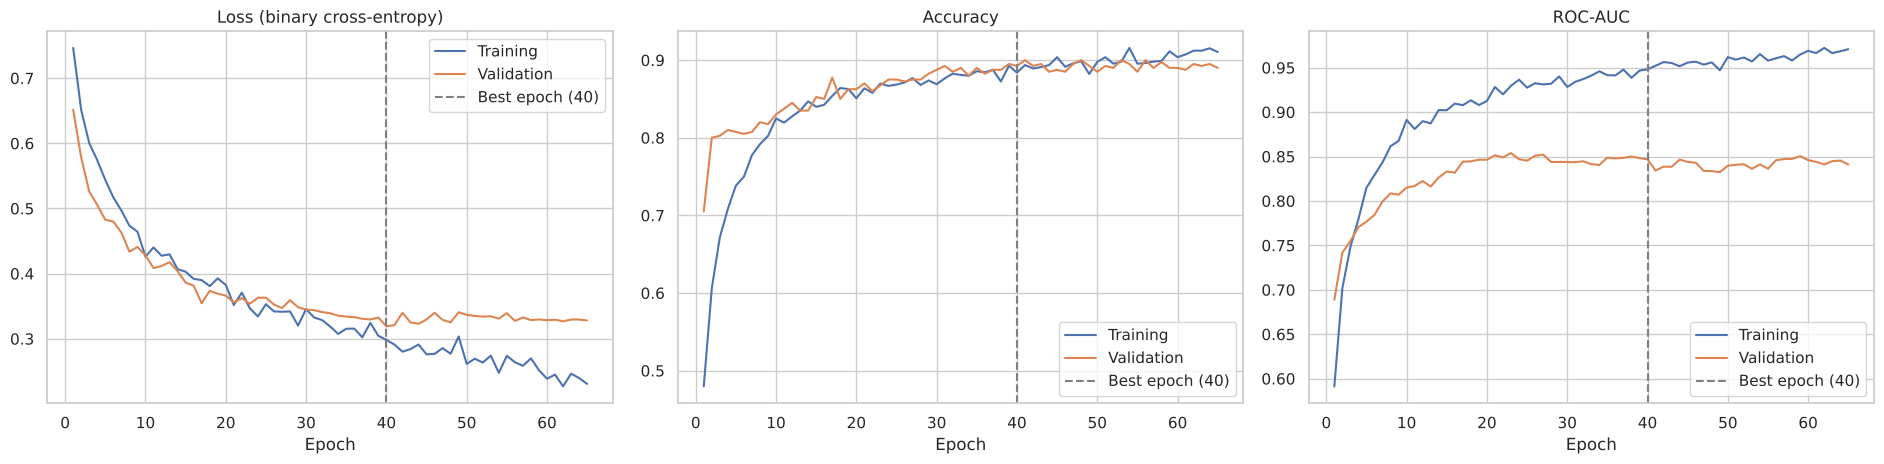

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, m, title in zip(axes, ["loss", "accuracy", "auc"], ["Loss (binary cross-entropy)", "Accuracy", "ROC-AUC"]):
    ax.plot(hist.index + 1, hist[m], label="Training")
    ax.plot(hist.index + 1, hist[f"val_{m}"], label="Validation")
    ax.axvline(best_epoch, color="grey", ls="--", label=f"Best epoch ({best_epoch})")
    ax.set_xlabel("Epoch"); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.savefig(IMG / "training_curves.png", dpi=120); plt.show()

## 5. Evaluation on the held-out test set

In [7]:
test_metrics = model.evaluate(X_test, y_test, verbose=0, return_dict=True)
print({k: round(v, 4) for k, v in test_metrics.items()})

proba = model.predict(X_test, verbose=0).ravel()
pred = (proba >= 0.5).astype(int)
print(f"\nTest accuracy : {accuracy_score(y_test, pred):.3f}")
print(f"Precision     : {precision_score(y_test, pred):.3f}")
print(f"Recall        : {recall_score(y_test, pred):.3f}")
print(f"F1            : {f1_score(y_test, pred):.3f}")
print(f"ROC-AUC       : {roc_auc_score(y_test, proba):.3f}\n")
print(classification_report(y_test, pred, target_names=["Stay", "Churn"], digits=3))

{'accuracy': 0.8981, 'auc': 0.9244, 'loss': 0.279, 'precision': 0.608, 'recall': 0.8}



Test accuracy : 0.898
Precision     : 0.608
Recall        : 0.800
F1            : 0.691
ROC-AUC       : 0.925

              precision    recall  f1-score   support

        Stay      0.965     0.914     0.939       572
       Churn      0.608     0.800     0.691        95

    accuracy                          0.898       667
   macro avg      0.786     0.857     0.815       667
weighted avg      0.914     0.898     0.904       667



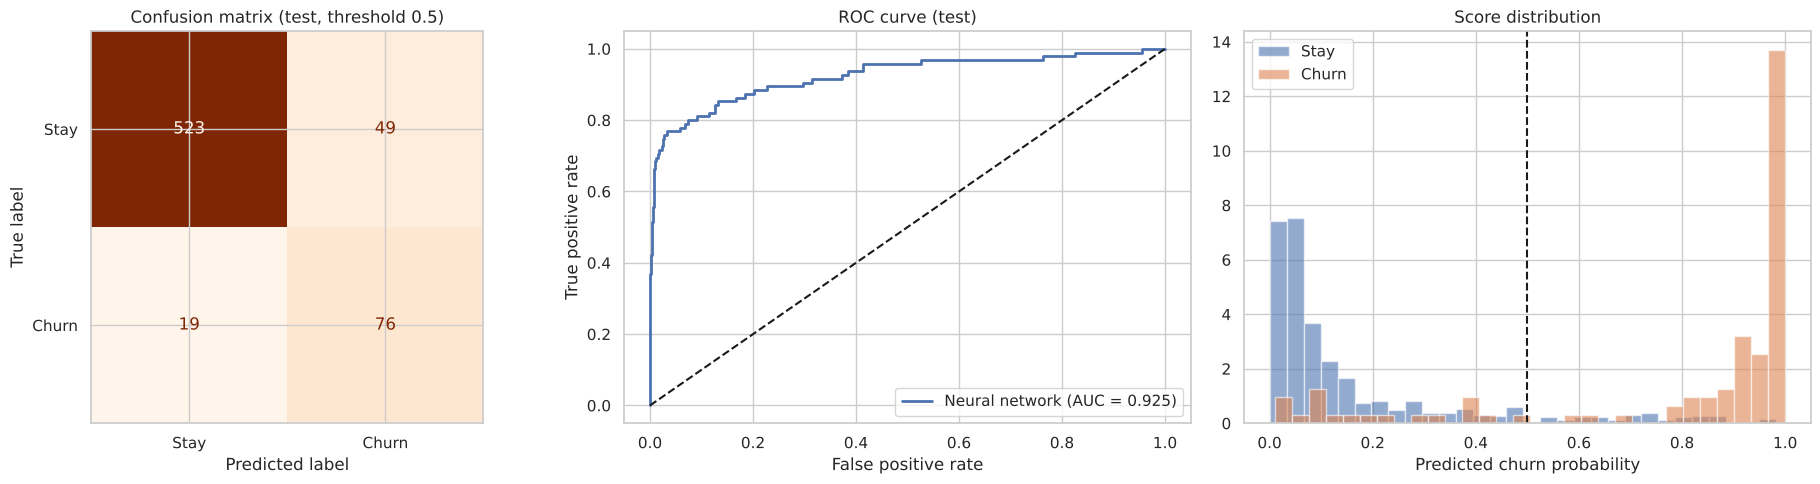

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stay", "Churn"], cmap="Oranges", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix (test, threshold 0.5)")
fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, lw=2, label=f"Neural network (AUC = {roc_auc_score(y_test, proba):.3f})")
axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve (test)"); axes[1].legend(loc="lower right")
axes[2].hist(proba[y_test == 0], bins=30, alpha=.6, label="Stay", density=True)
axes[2].hist(proba[y_test == 1], bins=30, alpha=.6, label="Churn", density=True)
axes[2].axvline(.5, color="k", ls="--"); axes[2].set_xlabel("Predicted churn probability"); axes[2].set_title("Score distribution")
axes[2].legend()
plt.tight_layout(); plt.savefig(IMG / "evaluation.png", dpi=120); plt.show()

### Comparison with a model without regularisation
To show why dropout / batch-norm / early stopping are in the architecture, we train the same network **without** them for a fixed
200 epochs and compare the curves.

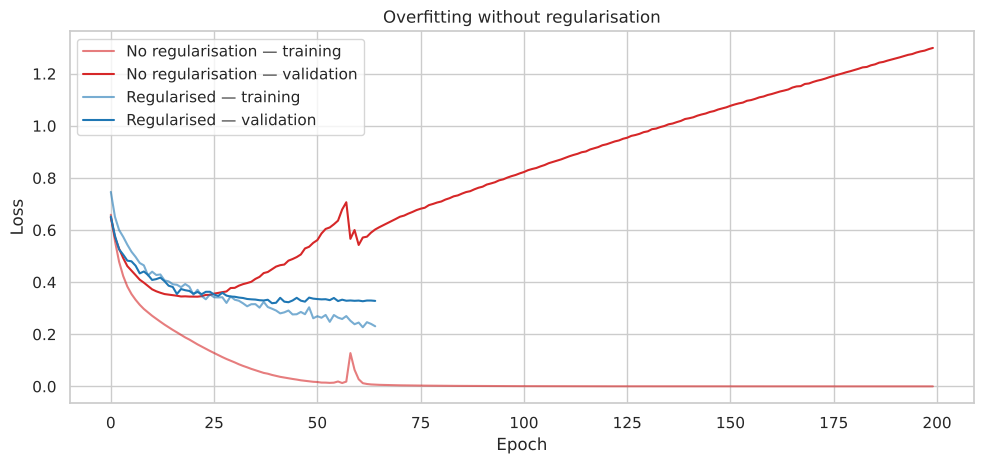

,Test accuracy,Test F1,Test AUC,Min val loss,Final val loss
Model,,,,,
Regularised NN (final),0.898,0.691,0.925,0.319,0.328
Plain NN (no dropout/BN/early stop),0.921,0.717,0.887,0.344,1.299


In [9]:
tf.random.set_seed(SEED)
plain = keras.Sequential([layers.Input(shape=(X_tr.shape[1],)), layers.Dense(64, activation="relu"),
                          layers.Dense(32, activation="relu"), layers.Dense(16, activation="relu"),
                          layers.Dense(1, activation="sigmoid")])
plain.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
h_plain = pd.DataFrame(plain.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=200, batch_size=32,
                                 class_weight=class_weight, verbose=0).history)
p_plain = plain.predict(X_test, verbose=0).ravel()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(h_plain["loss"], label="No regularisation — training", color="tab:red", alpha=.6)
ax.plot(h_plain["val_loss"], label="No regularisation — validation", color="tab:red")
ax.plot(hist["loss"], label="Regularised — training", color="tab:blue", alpha=.6)
ax.plot(hist["val_loss"], label="Regularised — validation", color="tab:blue")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.set_title("Overfitting without regularisation"); ax.legend()
plt.tight_layout(); plt.savefig(IMG / "overfitting_comparison.png", dpi=120); plt.show()

pd.DataFrame({
    "Model": ["Regularised NN (final)", "Plain NN (no dropout/BN/early stop)"],
    "Test accuracy": [accuracy_score(y_test, pred), accuracy_score(y_test, (p_plain >= .5).astype(int))],
    "Test F1": [f1_score(y_test, pred), f1_score(y_test, (p_plain >= .5).astype(int))],
    "Test AUC": [roc_auc_score(y_test, proba), roc_auc_score(y_test, p_plain)],
    "Min val loss": [hist["val_loss"].min(), h_plain["val_loss"].min()],
    "Final val loss": [hist["val_loss"].iloc[-1], h_plain["val_loss"].iloc[-1]],
}).set_index("Model").round(3)

In [10]:
Path("output").mkdir(exist_ok=True)
model.save("output/churn_nn.keras")
print("Model saved to output/churn_nn.keras")

Model saved to output/churn_nn.keras


## Conclusions
**Architecture:** 14 inputs → 64 → 32 → 16 ReLU units (with batch-norm, dropout 0.3 and L2) → 1 sigmoid output;
~4k trainable parameters, trained with Adam + binary cross-entropy and class weights (0.59 / 3.43).

**Training:** early stopping ended training after 65 epochs and restored the weights from **epoch 40** (lowest validation loss
0.319). Training and validation losses fall together until ~epoch 40; after that the training loss keeps dropping while the
validation loss flattens (the start of overfitting) — exactly the point where early stopping keeps the best weights.

**Test-set results (667 unseen customers):**
| Metric | Value |
|---|---|
| **Accuracy** | **0.898** |
| Precision (churn) | 0.608 |
| Recall (churn) | **0.800** |
| F1 (churn) | 0.691 |
| ROC-AUC | **0.925** |

The network finds **80 % of churners** with a ROC-AUC of 0.925 — better than logistic regression (0.82) and the RBF-SVM (0.92),
and close to the tuned Random Forest (0.935).

**Why regularisation matters:** the plain network (no dropout / batch-norm / early stopping) reaches a slightly higher accuracy
at the 0.5 threshold, but its validation loss explodes from 0.34 to **1.30** — it memorises the training data and becomes
over-confident, and its ranking quality (AUC 0.887) is clearly worse. The regularised model is the more trustworthy one.

**Note on the dataset:** the task brief mentions MNIST as an example; we used the provided churn dataset so that the
network solves a real business classification problem and can be compared directly with the other Level 2–3 models.